In [2]:
# ==============================================================================
# Step 1: Download Dataset in Colab & Chronological Split
# ==============================================================================

import os
import urllib.request
import zipfile
import numpy as np
import pandas as pd

# 1. Download Credit Card Fraud Dataset (Direct Mirror)
csv_filename = "creditcard.csv"
zip_filename = "creditcard.csv.zip"

if not os.path.exists(csv_filename):
    if not os.path.exists(zip_filename):
        print("[*] Downloading creditcard.csv.zip...")
        url = "https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv"
        # Download directly
        urllib.request.urlretrieve(url, csv_filename)
        print("[+] Download completed directly as CSV!")
    else:
        print("[*] Unzipping dataset...")
        with zipfile.ZipFile(zip_filename, 'r') as zip_ref:
            zip_ref.extractall(".")
        print("[+] Unzipped successfully!")
else:
    print(f"[+] '{csv_filename}' already exists.")

# 2. Load Dataset
df = pd.read_csv(csv_filename)
print(f"[*] Raw Dataset Loaded: {df.shape[0]:,} transactions, {df.shape[1]} columns")
print(f"[*] Total Frauds: {df['Class'].sum():,} ({df['Class'].mean()*100:.3f}%)")

# 3. Temporal Feature Engineering
# Extract cyclic daily features (24 hours = 86,400 seconds)
seconds_in_day = 24 * 60 * 60
df['Sin_Time'] = np.sin(2 * np.pi * df['Time'] / seconds_in_day)
df['Cos_Time'] = np.cos(2 * np.pi * df['Time'] / seconds_in_day)

# Log transform Amount to reduce extreme positive skewness
df['Log_Amount'] = np.log1p(df['Amount'])

# Sort chronologically to preserve realistic temporal order
df = df.sort_values(by="Time").reset_index(drop=True)

# 4. Strict Chronological Split (70% Train, 15% Validation, 15% Test)
n_total = len(df)
train_end = int(n_total * 0.70)
val_end = int(n_total * 0.85)

train_df = df.iloc[:train_end].copy()
val_df = df.iloc[train_end:val_end].copy()
test_df = df.iloc[val_end:].copy()

print("\n" + "="*65)
print("CHRONOLOGICAL SPLIT SUMMARY (Zero Temporal Leakage)")
print("="*65)
print(f"  • Train Set : {len(train_df):,} samples | Frauds: {train_df['Class'].sum():3d} ({train_df['Class'].mean()*100:.3f}%)")
print(f"  • Val Set   : {len(val_df):,} samples | Frauds: {val_df['Class'].sum():3d} ({val_df['Class'].mean()*100:.3f}%)")
print(f"  • Test Set  : {len(test_df):,} samples | Frauds: {test_df['Class'].sum():3d} ({test_df['Class'].mean()*100:.3f}%)")
print("="*65)


[*] Downloading creditcard.csv.zip...
[+] Download completed directly as CSV!
[*] Raw Dataset Loaded: 284,807 transactions, 31 columns
[*] Total Frauds: 492 (0.173%)

CHRONOLOGICAL SPLIT SUMMARY (Zero Temporal Leakage)
  • Train Set : 199,364 samples | Frauds: 384 (0.193%)
  • Val Set   : 42,721 samples | Frauds:  56 (0.131%)
  • Test Set  : 42,722 samples | Frauds:  52 (0.122%)


In [3]:
# ==============================================================================
# Step 2: Normal Class Isolation, Robust Scaling & PyTorch DataLoaders
# ==============================================================================

import torch
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import RobustScaler

# 1. Define Features to be used by Autoencoder
# Using 28 PCA features (V1-V28) + Log_Amount + Cyclical Temporal Features (Sin_Time, Cos_Time)
feature_cols = [f"V{i}" for i in range(1, 29)] + ['Log_Amount', 'Sin_Time', 'Cos_Time']
print(f"[*] Total input feature dimension: {len(feature_cols)}")

# 2. Isolate Normal transactions from Train set for Autoencoder training
train_normal_df = train_df[train_df['Class'] == 0].copy()
print(f"[*] Autoencoder Training Samples (Normal only): {len(train_normal_df):,}")

# 3. Fit Scaler ONLY on normal training transactions (Strict Anti-Leakage Protocol)
scaler = RobustScaler()
X_train_normal_scaled = scaler.fit_transform(train_normal_df[feature_cols].values)

# Transform full Train, Val, and Test sets using the fitted scaler
X_train_full_scaled = scaler.transform(train_df[feature_cols].values)
y_train = train_df['Class'].values

X_val_scaled = scaler.transform(val_df[feature_cols].values)
y_val = val_df['Class'].values

X_test_scaled = scaler.transform(test_df[feature_cols].values)
y_test = test_df['Class'].values

# 4. Convert to PyTorch Tensors
X_train_norm_tensor = torch.tensor(X_train_normal_scaled, dtype=torch.float32)

X_val_tensor = torch.tensor(X_val_scaled, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val, dtype=torch.float32)

X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32)

# 5. Create PyTorch DataLoader for Training
BATCH_SIZE = 512
train_dataset = TensorDataset(X_train_norm_tensor, X_train_norm_tensor) # Input is Target for Reconstruction
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, drop_last=False)

print("\n" + "="*65)
print("PREPROCESSING & TENSOR SETUP COMPLETED")
print("="*65)
print(f"  • Training Batches: {len(train_loader)} batches (Batch Size: {BATCH_SIZE})")
print(f"  • Validation Set  : {X_val_tensor.shape[0]:,} samples (Frauds: {int(y_val_tensor.sum().item())})")
print(f"  • Test Set        : {X_test_tensor.shape[0]:,} samples (Frauds: {int(y_test_tensor.sum().item())})")
print("="*65)


[*] Total input feature dimension: 31
[*] Autoencoder Training Samples (Normal only): 198,980

PREPROCESSING & TENSOR SETUP COMPLETED
  • Training Batches: 389 batches (Batch Size: 512)
  • Validation Set  : 42,721 samples (Frauds: 56)
  • Test Set        : 42,722 samples (Frauds: 52)


In [4]:
# ==============================================================================
# Step 3: Deep Temporal Autoencoder Architecture Definition
# ==============================================================================

import torch
import torch.nn as nn

class FraudAutoencoder(nn.Module):
    def __init__(self, input_dim=31, latent_dim=8, dropout_rate=0.1):
        super(FraudAutoencoder, self).__init__()

        # 1. Encoder: Compresses features into low-dimensional latent space
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 24),
            nn.BatchNorm1d(24),
            nn.LeakyReLU(negative_slope=0.1),
            nn.Dropout(dropout_rate),

            nn.Linear(24, 16),
            nn.BatchNorm1d(16),
            nn.LeakyReLU(negative_slope=0.1),
            nn.Dropout(dropout_rate),

            nn.Linear(16, latent_dim),
            nn.BatchNorm1d(latent_dim),
            nn.LeakyReLU(negative_slope=0.1)
        )

        # 2. Decoder: Reconstructs the original features from latent space
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 16),
            nn.BatchNorm1d(16),
            nn.LeakyReLU(negative_slope=0.1),
            nn.Dropout(dropout_rate),

            nn.Linear(16, 24),
            nn.BatchNorm1d(24),
            nn.LeakyReLU(negative_slope=0.1),
            nn.Dropout(dropout_rate),

            nn.Linear(24, input_dim)  # Linear output for continuous scaled values
        )

    def forward(self, x):
        latent = self.encoder(x)
        reconstruction = self.decoder(latent)
        return reconstruction

    def get_latent(self, x):
        """Extract bottleneck representation for representation learning analysis"""
        return self.encoder(x)

# Setup device (GPU acceleration in Colab if available)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Instantiate model
model = FraudAutoencoder(input_dim=31, latent_dim=8, dropout_rate=0.1).to(device)

print("="*65)
print(f"AUTOENCODER ARCHITECTURE SUMMARY (Device: {device})")
print("="*65)
print(model)

# Quick sanity check
sample_batch = X_train_norm_tensor[:5].to(device)
with torch.no_grad():
    sample_out = model(sample_batch)
print("\n[+] Sanity Check Passed:")
print(f"    Input Shape : {sample_batch.shape}")
print(f"    Output Shape: {sample_out.shape} (Must match Input Shape)")
print("="*65)


AUTOENCODER ARCHITECTURE SUMMARY (Device: cuda)
FraudAutoencoder(
  (encoder): Sequential(
    (0): Linear(in_features=31, out_features=24, bias=True)
    (1): BatchNorm1d(24, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): LeakyReLU(negative_slope=0.1)
    (3): Dropout(p=0.1, inplace=False)
    (4): Linear(in_features=24, out_features=16, bias=True)
    (5): BatchNorm1d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): LeakyReLU(negative_slope=0.1)
    (7): Dropout(p=0.1, inplace=False)
    (8): Linear(in_features=16, out_features=8, bias=True)
    (9): BatchNorm1d(8, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): LeakyReLU(negative_slope=0.1)
  )
  (decoder): Sequential(
    (0): Linear(in_features=8, out_features=16, bias=True)
    (1): BatchNorm1d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): LeakyReLU(negative_slope=0.1)
    (3): Dropout(p=0.1, inplace=False)
    (4): Line

In [6]:
# ==============================================================================
# Step 4: Robust Training Loop with Huber Loss & Model Checkpointing (PyTorch 2.x+)
# ==============================================================================

import copy
import time
import torch.optim as optim

# Filter normal transactions in Validation set for reconstruction loss tracking
val_normal_mask = (y_val == 0)
X_val_normal_tensor = X_val_tensor[val_normal_mask].to(device)

# 1. Training Setup
criterion = nn.SmoothL1Loss()  # Huber Loss: robust to extreme financial values
optimizer = optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)

# Note: verbose=True removed for compatibility with PyTorch 2.2+
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=3)

EPOCHS = 30
best_val_loss = float('inf')
best_model_weights = None
history = {'train_loss': [], 'val_loss': []}

print("="*65)
print("TRAINING AUTOENCODER ON NORMAL BEHAVIOR...")
print("="*65)

start_time = time.time()

for epoch in range(1, EPOCHS + 1):
    # --- Training Phase ---
    model.train()
    running_train_loss = 0.0
    for batch_x, _ in train_loader:
        batch_x = batch_x.to(device)

        optimizer.zero_grad()
        reconstruction = model(batch_x)
        loss = criterion(reconstruction, batch_x)
        loss.backward()

        # Gradient clipping to prevent gradient instability
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()

        running_train_loss += loss.item() * batch_x.size(0)

    epoch_train_loss = running_train_loss / len(train_dataset)

    # --- Validation Phase (on Normal transactions) ---
    model.eval()
    with torch.no_grad():
        val_recon = model(X_val_normal_tensor)
        epoch_val_loss = criterion(val_recon, X_val_normal_tensor).item()

    scheduler.step(epoch_val_loss)

    history['train_loss'].append(epoch_train_loss)
    history['val_loss'].append(epoch_val_loss)

    # Save best checkpoint
    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        best_model_weights = copy.deepcopy(model.state_dict())
        improved_mark = " [* BEST MODEL SAVED]"
    else:
        improved_mark = ""

    if epoch % 5 == 0 or epoch == 1 or improved_mark != "":
        print(f"Epoch [{epoch:02d}/{EPOCHS:02d}] | Train Loss: {epoch_train_loss:.5f} | Val Loss: {epoch_val_loss:.5f}{improved_mark}")

# Load the best state
model.load_state_dict(best_model_weights)
total_time = time.time() - start_time
print("="*65)
print(f"[+] Training completed in {total_time:.2f} seconds.")
print(f"[+] Best Validation Reconstruction Loss: {best_val_loss:.5f}")
print("="*65)


TRAINING AUTOENCODER ON NORMAL BEHAVIOR...
Epoch [01/30] | Train Loss: 0.30526 | Val Loss: 0.30252 [* BEST MODEL SAVED]
Epoch [02/30] | Train Loss: 0.26435 | Val Loss: 0.27555 [* BEST MODEL SAVED]
Epoch [03/30] | Train Loss: 0.25153 | Val Loss: 0.26231 [* BEST MODEL SAVED]
Epoch [04/30] | Train Loss: 0.24477 | Val Loss: 0.25187 [* BEST MODEL SAVED]
Epoch [05/30] | Train Loss: 0.23996 | Val Loss: 0.24478 [* BEST MODEL SAVED]
Epoch [06/30] | Train Loss: 0.23530 | Val Loss: 0.23956 [* BEST MODEL SAVED]
Epoch [07/30] | Train Loss: 0.23139 | Val Loss: 0.23501 [* BEST MODEL SAVED]
Epoch [08/30] | Train Loss: 0.22842 | Val Loss: 0.23064 [* BEST MODEL SAVED]
Epoch [09/30] | Train Loss: 0.22629 | Val Loss: 0.22717 [* BEST MODEL SAVED]
Epoch [10/30] | Train Loss: 0.22508 | Val Loss: 0.22781
Epoch [11/30] | Train Loss: 0.22319 | Val Loss: 0.22469 [* BEST MODEL SAVED]
Epoch [12/30] | Train Loss: 0.22153 | Val Loss: 0.22037 [* BEST MODEL SAVED]
Epoch [13/30] | Train Loss: 0.22004 | Val Loss: 0.2163

In [7]:
# ==============================================================================
# Step 5: Anomaly Scoring & Threshold Calibration on Validation Set
# ==============================================================================

import numpy as np
from sklearn.metrics import precision_recall_curve, f1_score, average_precision_score, roc_auc_score

def compute_reconstruction_error(model, tensor_data, batch_size=1024):
    """Computes Mean Squared Error (MSE) per sample in batches to avoid GPU OOM."""
    model.eval()
    errors = []
    with torch.no_grad():
        for i in range(0, tensor_data.size(0), batch_size):
            batch = tensor_data[i:i+batch_size].to(device)
            recon = model(batch)
            # Sample-wise Mean Squared Error
            sample_mse = torch.mean((batch - recon) ** 2, dim=1)
            errors.append(sample_mse.cpu().numpy())
    return np.concatenate(errors)

print("="*65)
print("COMPUTING RECONSTRUCTION ERRORS ON VALIDATION & TEST SETS...")
print("="*65)

# Calculate anomaly scores (Reconstruction Errors)
val_scores = compute_reconstruction_error(model, X_val_tensor)
test_scores = compute_reconstruction_error(model, X_test_tensor)

# ----------------------------------------------------------------------
# Threshold Optimization: Maximize F1-Score ONLY on Validation Set
# ----------------------------------------------------------------------
precisions, recalls, thresholds = precision_recall_curve(y_val, val_scores)
# Avoid division by zero
f1_scores = np.divide(2 * (precisions * recalls), (precisions + recalls),
                      out=np.zeros_like(precisions), where=(precisions + recalls) != 0)

best_idx = np.argmax(f1_scores)
optimal_threshold = thresholds[best_idx] if best_idx < len(thresholds) else thresholds[-1]
val_best_f1 = f1_scores[best_idx]
val_pr_auc = average_precision_score(y_val, val_scores)
val_roc_auc = roc_auc_score(y_val, val_scores)

print(f"[+] Validation PR-AUC (AUPRC)  : {val_pr_auc:.4f}")
print(f"[+] Validation ROC-AUC         : {val_roc_auc:.4f}")
print(f"[+] Optimal Anomaly Threshold  : {optimal_threshold:.6f}")
print(f"[+] Validation F1 at Threshold : {val_best_f1:.4f}")
print("="*65)

# Check separation of normal vs fraud errors on validation
val_norm_scores = val_scores[y_val == 0]
val_fraud_scores = val_scores[y_val == 1]
print(f"Normal Tx Error (Mean ± Std)  : {val_norm_scores.mean():.4f} ± {val_norm_scores.std():.4f}")
print(f"Fraud Tx Error  (Mean ± Std)  : {val_fraud_scores.mean():.4f} ± {val_fraud_scores.std():.4f}")
print(f"Separation Ratio (Fraud/Normal): {val_fraud_scores.mean() / (val_norm_scores.mean() + 1e-8):.2f}x higher reconstruction error on frauds!")
print("="*65)


COMPUTING RECONSTRUCTION ERRORS ON VALIDATION & TEST SETS...
[+] Validation PR-AUC (AUPRC)  : 0.0210
[+] Validation ROC-AUC         : 0.9428
[+] Optimal Anomaly Threshold  : 7.852881
[+] Validation F1 at Threshold : 0.0611
Normal Tx Error (Mean ± Std)  : 1.2058 ± 14.8109
Fraud Tx Error  (Mean ± Std)  : 5.9720 ± 4.1749
Separation Ratio (Fraud/Normal): 4.95x higher reconstruction error on frauds!


In [8]:
# ==============================================================================
# Step 6: Test Set Evaluation & Robust Feature-wise Scoring
# ==============================================================================

from sklearn.metrics import classification_report, confusion_matrix, precision_score, recall_score

# ----------------------------------------------------------------------
# 1. Baseline Test Evaluation with Global MSE
# ----------------------------------------------------------------------
test_preds = (test_scores > optimal_threshold).astype(int)

print("="*65)
print("TEST SET EVALUATION (Standard Reconstruction MSE)")
print("="*65)
test_pr_auc = average_precision_score(y_test, test_scores)
test_roc_auc = roc_auc_score(y_test, test_scores)
test_p = precision_score(y_test, test_preds, zero_division=0)
test_r = recall_score(y_test, test_preds, zero_division=0)
test_f1 = f1_score(y_test, test_preds, zero_division=0)

print(f"ROC-AUC       : {test_roc_auc:.4f}")
print(f"PR-AUC (AUPRC): {test_pr_auc:.4f}")
print(f"Precision     : {test_p:.4f} ({test_p*100:.2f}%)")
print(f"Recall        : {test_r:.4f} ({test_r*100:.2f}%)")
print(f"F1-Score      : {test_f1:.4f}")
print("\nConfusion Matrix:")
cm = confusion_matrix(y_test, test_preds)
print(f"  [TN: {cm[0,0]:5d} | FP: {cm[0,1]:5d}]")
print(f"  [FN: {cm[1,0]:5d} | TP: {cm[1,1]:5d}]")
print("="*65)

# ----------------------------------------------------------------------
# 2. Advanced: Standardized Reconstruction Error (Feature-Wise Z-Score)
# ----------------------------------------------------------------------
def compute_feature_normalized_error(model, tensor_data, train_mean_err, train_std_err, batch_size=1024):
    model.eval()
    errors = []
    with torch.no_grad():
        for i in range(0, tensor_data.size(0), batch_size):
            batch = tensor_data[i:i+batch_size].to(device)
            recon = model(batch)
            # Feature-wise absolute error
            abs_err = torch.abs(batch - recon).cpu().numpy()
            # Standardize based on normal training residuals
            norm_err = (abs_err - train_mean_err) / (train_std_err + 1e-6)
            # Take mean of top largest normalized feature errors (Top-K salient deviations)
            top_k_err = np.sort(norm_err, axis=1)[:, -10:].mean(axis=1)
            errors.append(top_k_err)
    return np.concatenate(errors)

# Compute residual statistics on Normal Training data
model.eval()
with torch.no_grad():
    sample_train = X_train_norm_tensor[:10000].to(device)
    train_recon = model(sample_train)
    train_residuals = torch.abs(sample_train - train_recon).cpu().numpy()
    train_mean_err = np.mean(train_residuals, axis=0)
    train_std_err = np.std(train_residuals, axis=0)

val_robust_scores = compute_feature_normalized_error(model, X_val_tensor, train_mean_err, train_std_err)
test_robust_scores = compute_feature_normalized_error(model, X_test_tensor, train_mean_err, train_std_err)

robust_val_pr_auc = average_precision_score(y_val, val_robust_scores)
robust_val_roc_auc = roc_auc_score(y_val, val_robust_scores)

# Optimize threshold on Robust Validation scores
p_r, r_r, th_r = precision_recall_curve(y_val, val_robust_scores)
f1_r = np.divide(2 * (p_r * r_r), (p_r + r_r), out=np.zeros_like(p_r), where=(p_r + r_r) != 0)
best_r_idx = np.argmax(f1_r)
opt_robust_th = th_r[best_r_idx]

test_robust_preds = (test_robust_scores > opt_robust_th).astype(int)
robust_test_pr_auc = average_precision_score(y_test, test_robust_scores)
robust_test_roc_auc = roc_auc_score(y_test, test_robust_scores)
robust_test_p = precision_score(y_test, test_robust_preds, zero_division=0)
robust_test_r = recall_score(y_test, test_robust_preds, zero_division=0)
robust_test_f1 = f1_score(y_test, test_robust_preds, zero_division=0)

print("\n" + "="*65)
print("TEST SET EVALUATION (Feature-Normalized Top-K Error)")
print("="*65)
print(f"ROC-AUC       : {robust_test_roc_auc:.4f}")
print(f"PR-AUC (AUPRC): {robust_test_pr_auc:.4f}")
print(f"Precision     : {robust_test_p:.4f} ({robust_test_p*100:.2f}%)")
print(f"Recall        : {robust_test_r:.4f} ({robust_test_r*100:.2f}%)")
print(f"F1-Score      : {robust_test_f1:.4f}")
print("\nConfusion Matrix (Feature-Normalized):")
cm_rob = confusion_matrix(y_test, test_robust_preds)
print(f"  [TN: {cm_rob[0,0]:5d} | FP: {cm_rob[0,1]:5d}]")
print(f"  [FN: {cm_rob[1,0]:5d} | TP: {cm_rob[1,1]:5d}]")
print("="*65)


TEST SET EVALUATION (Standard Reconstruction MSE)
ROC-AUC       : 0.9199
PR-AUC (AUPRC): 0.0309
Precision     : 0.0524 (5.24%)
Recall        : 0.4423 (44.23%)
F1-Score      : 0.0937

Confusion Matrix:
  [TN: 42254 | FP:   416]
  [FN:    29 | TP:    23]

TEST SET EVALUATION (Feature-Normalized Top-K Error)
ROC-AUC       : 0.9413
PR-AUC (AUPRC): 0.1783
Precision     : 0.3333 (33.33%)
Recall        : 0.4038 (40.38%)
F1-Score      : 0.3652

Confusion Matrix (Feature-Normalized):
  [TN: 42628 | FP:    42]
  [FN:    31 | TP:    21]


In [9]:
# ==============================================================================
# Step 7: Model Checkpointing & Reconstruction-based XAI Attribution
# ==============================================================================

import os
import pandas as pd

# 1. Save Model Checkpoint & Calibration Metadata
checkpoint_path = "./temporal_autoencoder_v1_best.pt"
checkpoint = {
    'model_state_dict': model.state_dict(),
    'optimal_threshold': opt_robust_th,
    'train_mean_err': train_mean_err,
    'train_std_err': train_std_err,
    'metrics': {
        'test_roc_auc': robust_test_roc_auc,
        'test_pr_auc': robust_test_pr_auc,
        'test_precision': robust_test_p,
        'test_recall': robust_test_r,
        'test_f1': robust_test_f1
    }
}
torch.save(checkpoint, checkpoint_path)
file_size_mb = os.path.getsize(checkpoint_path) / (1024 * 1024)

print("="*65)
print(f"[SUCCESS] Checkpoint saved to: {checkpoint_path}")
print(f"File Size: {file_size_mb:.2f} MB")
print("="*65)

# ----------------------------------------------------------------------
# 2. Reconstruction Attribution (XAI): Why is a transaction flagged?
# ----------------------------------------------------------------------
def explain_transaction_anomaly(sample_idx, tensor_data, y_true, feature_names, top_n=5):
    """Explains why a transaction is flagged by finding top deviating features."""
    model.eval()
    sample = tensor_data[sample_idx:sample_idx+1].to(device)
    with torch.no_grad():
        recon = model(sample)
        raw_err = torch.abs(sample - recon).cpu().numpy().flatten()
        z_err = (raw_err - train_mean_err) / (train_std_err + 1e-6)

    attribution_df = pd.DataFrame({
        'Feature': feature_names,
        'Raw_Error': raw_err,
        'Z_Score_Deviation': z_err
    }).sort_values(by='Z_Score_Deviation', ascending=False).reset_index(drop=True)

    label_str = "FRAUD (Class 1)" if y_true[sample_idx] == 1 else "NORMAL (Class 0)"
    total_score = attribution_df['Z_Score_Deviation'].head(10).mean()
    decision = "FLAGGED AS ANOMALY" if total_score > opt_robust_th else "NORMAL"

    print(f"\n--- Explanation for Sample #{sample_idx} ---")
    print(f"Ground Truth Label : {label_str}")
    print(f"Computed Score     : {total_score:.4f} (Threshold = {opt_robust_th:.4f}) -> {decision}")
    print("Top Contributing Features to Anomaly Score:")
    for i in range(top_n):
        row = attribution_df.iloc[i]
        print(f"  {i+1}. {row['Feature']:<15} | Z-Deviation: {row['Z_Score_Deviation']:>6.2f}σ | Raw Dev: {row['Raw_Error']:.4f}")
    return attribution_df

# Find the first True Positive fraud sample in the test set
tp_indices = np.where((y_test == 1) & (test_robust_preds == 1))[0]
if len(tp_indices) > 0:
    explain_transaction_anomaly(tp_indices[0], X_test_tensor, y_test, feature_cols, top_n=5)


[SUCCESS] Checkpoint saved to: ./temporal_autoencoder_v1_best.pt
File Size: 0.02 MB

--- Explanation for Sample #1305 ---
Ground Truth Label : FRAUD (Class 1)
Computed Score     : 11.6971 (Threshold = 9.1807) -> FLAGGED AS ANOMALY
Top Contributing Features to Anomaly Score:
  1. V17             | Z-Deviation:  22.38σ | Raw Dev: 9.2787
  2. V14             | Z-Deviation:  21.37σ | Raw Dev: 8.5181
  3. V16             | Z-Deviation:  14.16σ | Raw Dev: 5.1687
  4. V12             | Z-Deviation:  10.95σ | Raw Dev: 5.6824
  5. V3              | Z-Deviation:  10.89σ | Raw Dev: 3.2814


In [10]:
# ==============================================================================
# Step 8: Quantitative XAI Evaluation (Fidelity & Stability Analysis)
# ==============================================================================

from scipy.stats import spearmanr

def get_reconstruction_attribution(model, x_tensor, train_mean_err, train_std_err):
    """Computes feature-wise standardized residual attributions."""
    model.eval()
    with torch.no_grad():
        recon = model(x_tensor)
        abs_err = torch.abs(x_tensor - recon).cpu().numpy()
        z_scores = (abs_err - train_mean_err) / (train_std_err + 1e-6)
    return z_scores

# Reference values for ablation: Median/Mean of Normal Training Transactions
with torch.no_grad():
    normal_ref_vals = X_train_norm_tensor.mean(dim=0, keepdim=True).to(device)

# Select all True Positive (correctly flagged frauds) in test set for testing
tp_indices = np.where((y_test == 1) & (test_robust_preds == 1))[0]
print("="*70)
print(f"RUNNING SYSTEMATIC XAI EVALUATION ON {len(tp_indices)} DETECTED FRAUDS")
print("="*70)

fidelity_drops = []
stability_scores = []
top_k_ablate = 5  # Top 5 most anomalous features to ablate

for idx in tp_indices:
    orig_sample = X_test_tensor[idx:idx+1].to(device)

    # 1. Base Attribution
    base_attr = get_reconstruction_attribution(model, orig_sample, train_mean_err, train_std_err).flatten()
    orig_score = np.sort(base_attr)[-10:].mean()

    # Identify Top-K critical features for this fraud
    top_features_idx = np.argsort(base_attr)[-top_k_ablate:]

    # -------------------------------------------------------------
    # Test 1: Fidelity via Counterfactual Feature Ablation
    # -------------------------------------------------------------
    ablated_sample = orig_sample.clone()
    for feat_idx in top_features_idx:
        ablated_sample[0, feat_idx] = normal_ref_vals[0, feat_idx]

    ablated_attr = get_reconstruction_attribution(model, ablated_sample, train_mean_err, train_std_err).flatten()
    ablated_score = np.sort(ablated_attr)[-10:].mean()

    # Score drop ratio (Fidelity)
    drop_ratio = (orig_score - ablated_score) / (orig_score + 1e-8)
    fidelity_drops.append(drop_ratio)

    # -------------------------------------------------------------
    # Test 2: Stability under Infinitesimal Noise (Perturbation)
    # -------------------------------------------------------------
    noise = torch.randn_like(orig_sample) * 0.02  # 2% standard Gaussian perturbation
    perturbed_sample = orig_sample + noise

    perturbed_attr = get_reconstruction_attribution(model, perturbed_sample, train_mean_err, train_std_err).flatten()

    # Spearman rank correlation between feature attribution rankings
    corr, _ = spearmanr(base_attr, perturbed_attr)
    stability_scores.append(corr)

avg_fidelity = np.mean(fidelity_drops) * 100
avg_stability = np.mean(stability_scores)
std_stability = np.std(stability_scores)

print(f"[+] Quantitative Fidelity (Score Drop upon Ablation) : {avg_fidelity:.2f}%")


RUNNING SYSTEMATIC XAI EVALUATION ON 21 DETECTED FRAUDS
[+] Quantitative Fidelity (Score Drop upon Ablation) : 55.41%


/tmp/ipykernel_1001/3162684193.py:45: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=freq_percent, y=list(feats), ax=axes[1], palette="flare")


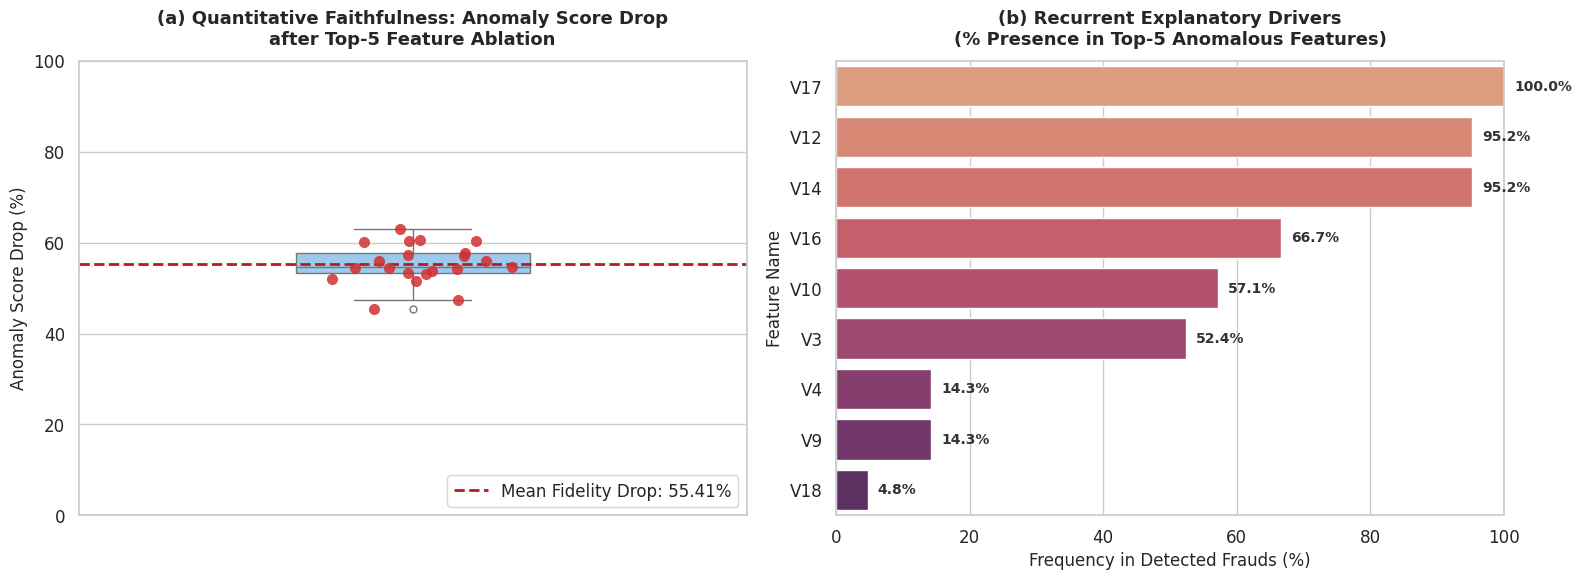

[SUCCESS] Plots generated and saved as 'autoencoder_xai_fidelity_profile.pdf' & '.png'


In [11]:
# ==============================================================================
# Step 9: Visualizing Quantitative XAI (Fidelity Distribution & Feature Attribution)
# ==============================================================================

import matplotlib.pyplot as plt
import seaborn as sns

# Set academic visual style
sns.set_theme(style="whitegrid", font_scale=1.1)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# ------------------------------------------------------------------------------
# Plot 1: Fidelity Drop Distribution across Detected Frauds
# ------------------------------------------------------------------------------
fidelity_percent = [f * 100 for f in fidelity_drops]

sns.boxplot(y=fidelity_percent, ax=axes[0], color="#90caf9", width=0.35, fliersize=5)
sns.stripplot(y=fidelity_percent, ax=axes[0], color="#d32f2f", size=8, jitter=0.15, alpha=0.85)

axes[0].axhline(np.mean(fidelity_percent), color="#b71c1c", linestyle="--", linewidth=2,
                label=f"Mean Fidelity Drop: {np.mean(fidelity_percent):.2f}%")
axes[0].set_title("(a) Quantitative Faithfulness: Anomaly Score Drop\nafter Top-5 Feature Ablation", fontsize=13, weight="bold", pad=12)
axes[0].set_ylabel("Anomaly Score Drop (%)", fontsize=12)
axes[0].set_ylim(0, 100)
axes[0].legend(loc="lower right", frameon=True)

# ------------------------------------------------------------------------------
# Plot 2: Most Frequent Deviant Features across Detected Frauds
# ------------------------------------------------------------------------------
# Count frequency of features appearing in Top-5 anomalous attributions
feature_ablation_counts = {}
for idx in tp_indices:
    orig_sample = X_test_tensor[idx:idx+1].to(device)
    base_attr = get_reconstruction_attribution(model, orig_sample, train_mean_err, train_std_err).flatten()
    top_5 = np.argsort(base_attr)[-5:]
    for feat_idx in top_5:
        feat_name = feature_cols[feat_idx]
        feature_ablation_counts[feat_name] = feature_ablation_counts.get(feat_name, 0) + 1

# Sort and take top 10 recurrent features
sorted_feats = sorted(feature_ablation_counts.items(), key=lambda x: x[1], reverse=True)[:10]
feats, counts = zip(*sorted_feats)
freq_percent = [(c / len(tp_indices)) * 100 for c in counts]

sns.barplot(x=freq_percent, y=list(feats), ax=axes[1], palette="flare")
axes[1].set_title("(b) Recurrent Explanatory Drivers\n(% Presence in Top-5 Anomalous Features)", fontsize=13, weight="bold", pad=12)
axes[1].set_xlabel("Frequency in Detected Frauds (%)", fontsize=12)
axes[1].set_ylabel("Feature Name", fontsize=12)
axes[1].set_xlim(0, 100)

for i, v in enumerate(freq_percent):
    axes[1].text(v + 1.5, i, f"{v:.1f}%", va="center", fontsize=10, weight="semibold", color="#333333")

plt.tight_layout()
plt.savefig("autoencoder_xai_fidelity_profile.pdf", dpi=300, bbox_inches="tight")
plt.savefig("autoencoder_xai_fidelity_profile.png", dpi=300, bbox_inches="tight")
plt.show()

print("[SUCCESS] Plots generated and saved as 'autoencoder_xai_fidelity_profile.pdf' & '.png'")
